# Reporte final: clasificación de 104 tipos de flores

Este notebook reproduce **de principio a fin** la tabla de resultados del reporte final
(`reports/final/resultados.csv`) y todas sus tablas y figuras.

- Repositorio: <https://github.com/Lunaaaalj/NeuralNetworksTeamEnvironment>
- Datos: competencia de Kaggle [Petals to the Metal](https://www.kaggle.com/competitions/tpu-getting-started) (TFRecords 224×224).
- Métrica principal: **F1 macro** sobre las 3,712 imágenes de validación (la misma métrica de Kaggle).

**Cómo correrlo**

```bash
uv venv --python 3.12 .venv && source .venv/bin/activate
uv pip install -r requirements.txt
python scripts/download_data.py          # requiere token de Kaggle
jupyter nbconvert --to notebook --execute --inplace notebooks/reporte_final.ipynb
```

Con `RUN_TRAINING = False` (valor por defecto) el notebook **no entrena**: reconstruye la tabla
a partir de los `history.csv`, `summary.json` y `eval_report.json` versionados en
`reports/final/experimentos/runs/`. Con `RUN_TRAINING = True` vuelve a entrenar y evaluar los
7 experimentos del reporte (≈2.5 h en una Mac M4 con `tensorflow-metal`; las corridas ya terminadas se conservan).


In [1]:
import json, subprocess, sys
from pathlib import Path

import pandas as pd
from IPython.display import Image, Markdown, display

ROOT = Path.cwd().resolve()
if not (ROOT / "src").exists():          # ejecutado desde notebooks/
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))

RUN_TRAINING = False   # True: reentrena los 7 experimentos del reporte (~2.5 h)
EXPERIMENTS = ROOT / "reports/final/experimentos"
REPORT = ROOT / "reports/final"
TFRECORDS = ROOT / "data/raw/tpu-getting-started/tfrecords-jpeg-224x224"
print("Raíz del repositorio:", ROOT)
print("TFRecords disponibles:", TFRECORDS.exists())

Raíz del repositorio: /Users/angelluna/Documents/STEM_PROJECTS/py/CNN-flower_classification/NeuralNetworksTeamEnvironment
TFRecords disponibles: True


## 1. Datos y desbalance de clases

Se cuentan las imágenes por clase leyendo solo la etiqueta de cada TFRecord. Si los datos no
están descargados, se usa el conteo versionado en `reports/final/experimentos/conteo_por_clase.csv`.

In [2]:
if TFRECORDS.exists():
    from src.classes import CLASSES
    from src.data import class_counts
    counts = pd.DataFrame({"label": range(104), "name": CLASSES,
                           "train": class_counts(TFRECORDS, "train"), "val": class_counts(TFRECORDS, "val")})
    counts.to_csv(EXPERIMENTS / "conteo_por_clase.csv", index=False)
else:
    counts = pd.read_csv(EXPERIMENTS / "conteo_por_clase.csv")
display(counts[["train", "val"]].describe().loc[["count", "min", "50%", "mean", "max"]].round(1))
display(counts.sort_values("train").iloc[[0, 1, 2, -3, -2, -1]])
print(f"Razón máx/mín en entrenamiento: {counts.train.max() / counts.train.min():.1f}x")

2026-10-22 08:54:24.601674: I metal_plugin/src/device/metal_device.cc:1154] Metal device set to: Apple M4
2026-10-22 08:54:24.601796: I metal_plugin/src/device/metal_device.cc:296] systemMemory: 16.00 GB
2026-10-22 08:54:24.601802: I metal_plugin/src/device/metal_device.cc:313] maxCacheSize: 5.92 GB
I0000 00:00:1792680864.602156 7491797 pluggable_device_factory.cc:305] Could not identify NUMA node of platform GPU ID 0, defaulting to 0. Your kernel may not have been built with NUMA support.
I0000 00:00:1792680864.602516 7491797 pluggable_device_factory.cc:271] Created TensorFlow device (/job:localhost/replica:0/task:0/device:GPU:0 with 0 MB memory) -> physical PluggableDevice (device: 0, name: METAL, pci bus id: <undefined>)
2026-10-22 08:54:24.679974: I tensorflow/core/kernels/data/tf_record_dataset_op.cc:370] TFRecordDataset `buffer_size` is unspecified, default to 262144


2026-10-22 08:54:24.862304: I tensorflow/core/framework/local_rendezvous.cc:405] Local rendezvous is aborting with status: OUT_OF_RANGE: End of sequence
2026-10-22 08:54:24.940000: I tensorflow/core/framework/local_rendezvous.cc:405] Local rendezvous is aborting with status: OUT_OF_RANGE: End of sequence


,train,val
count,104.0,104.0
min,18.0,5.0
50%,88.0,25.5
mean,122.6,35.7
max,782.0,228.0


,label,name,train,val
6,6,moon orchid,18,5
44,44,bolero deep blue,18,5
34,34,alpine sea holly,18,5
4,4,wild geranium,703,205
103,103,wild rose,743,216
67,67,iris,782,228


Razón máx/mín en entrenamiento: 43.4x


## 2. Experimentos

Cada experimento cambia **una sola cosa** respecto a la CNN de referencia
(`configs/final.yaml`: 4 convoluciones, dropout 0.5, aumento de datos, AdamW 0.01, LR 1e-3 con
reducción en meseta, 112×112, semilla 0). Los YAML derivados quedan en
`reports/final/experimentos/configs/`.

In [3]:
from scripts.run_final import EXPERIMENTS as MATRIX
display(pd.DataFrame([(label, group, description) for label, group, description, _ in MATRIX],
                     columns=["experimento", "grupo", "cambio respecto a la referencia"]))

,experimento,grupo,cambio respecto a la referencia
0,referencia,referencia,CNN original + dropout + aumento + AdamW + LR ...
1,mlp,arquitectura,MLP: 112x112x3 aplanada -> 256 -> 104 (LR 1e-4)
2,cnn_ampliada,arquitectura,"6 convoluciones (2 extra), misma política"
3,sin_regularizacion,regularizacion,"Sin dropout, sin aumento y sin weight decay"
4,class_weight,desbalance,Pérdida ponderada por clase (balanced)
5,lr_3e-4,hiperparametros,Tasa de aprendizaje 3e-4 (en vez de 1e-3)
6,dropout_0.3,hiperparametros,Dropout 0.3 (en vez de 0.5)
7,res_160,hiperparametros,Imágenes de 160x160 (en vez de 112x112)
8,sin_dropout,regularizacion,Sin dropout
9,sin_aumento,regularizacion,Sin aumento de datos


In [4]:
if RUN_TRAINING:
    subprocess.run([sys.executable, "-u", "-m", "scripts.run_final"], cwd=ROOT, check=True)
else:
    done = sorted(p.parent.parent.name for p in (EXPERIMENTS / "runs").glob("*/*/eval_report.json"))
    print(f"Se usan {len(done)} corridas guardadas:", ", ".join(done))

Se usan 7 corridas guardadas: class_weight, cnn_ampliada, dropout_0.3, lr_3e-4, mlp, referencia, sin_regularizacion


## 3. Tabla de resultados

`scripts/analyze_final.py` lee las corridas y escribe `resultados.csv`, las tablas LaTeX
(`reports/final/tablas/`) y las figuras (`reports/final/figures/`). Todas las métricas se
calculan en el checkpoint con mejor F1 macro de validación. *F1 entr.* se mide sobre 3,712 imágenes
fijas de entrenamiento **sin** aumento ni dropout, en esa misma época; la brecha es F1 entr. − F1 val.

In [5]:
subprocess.run([sys.executable, "-m", "scripts.analyze_final"], cwd=ROOT, check=True,
               stdout=subprocess.DEVNULL, stderr=subprocess.DEVNULL)
results = pd.read_csv(REPORT / "resultados.csv")
columns = ["experimento", "grupo", "parametros", "mejor_epoca", "epocas", "val_exactitud", "val_f1_macro",
           "train_f1_macro", "brecha_f1", "segundos_entrenamiento"]
display(results[columns].sort_values("val_f1_macro", ascending=False).reset_index(drop=True))

,experimento,grupo,parametros,mejor_epoca,epocas,val_exactitud,val_f1_macro,train_f1_macro,brecha_f1,segundos_entrenamiento
0,referencia,referencia,480936,91,103,0.6406,0.5784,0.8138,0.2354,1181.6
1,cnn_ampliada,arquitectura,1218600,41,49,0.6377,0.5663,0.7936,0.2273,1029.0
2,dropout_0.3,hiperparametros,480936,61,73,0.6196,0.5596,0.8157,0.2561,901.3
3,sin_regularizacion,regularizacion,480936,34,46,0.5964,0.5332,0.8767,0.3435,540.5
4,class_weight,desbalance,480936,70,82,0.4887,0.4881,0.6381,0.1500,1044.8
5,lr_3e-4,hiperparametros,480936,98,110,0.5418,0.4605,0.5541,0.0936,1350.8
6,mlp,arquitectura,9660776,62,74,0.1436,0.0178,0.0192,0.0014,414.4


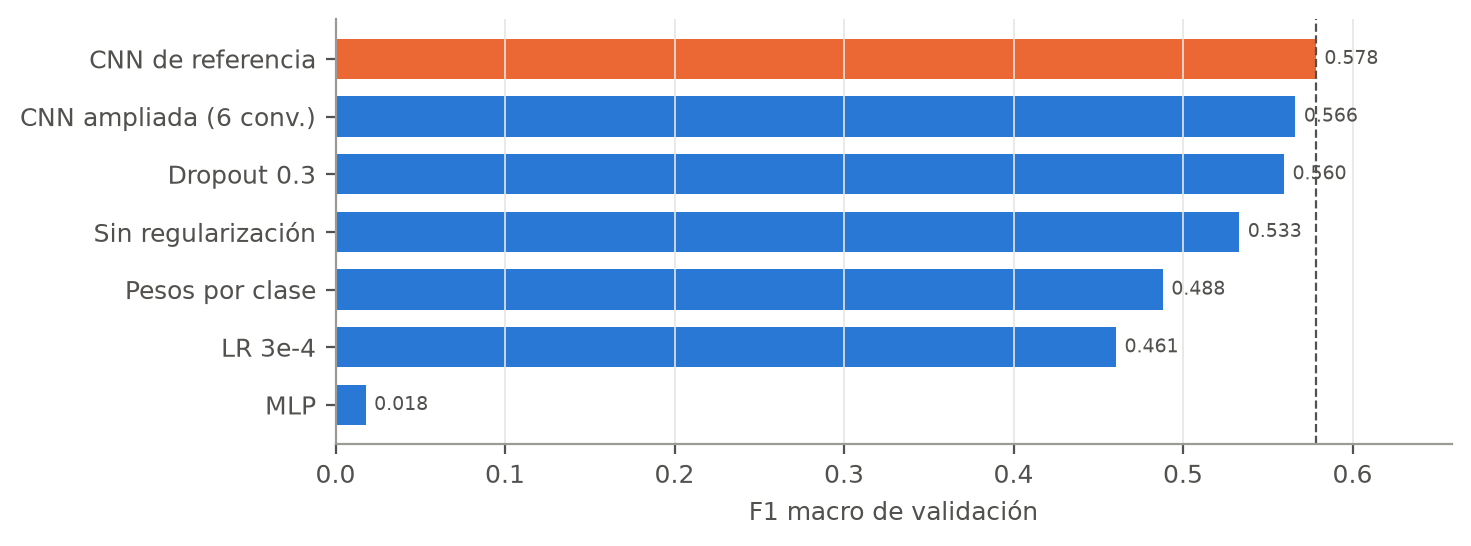

In [6]:
display(Image(filename=str(REPORT / "figures/comparacion_experimentos.png"), width=800))

## 4. Curvas de entrenamiento y validación (B1)

Pérdida, exactitud y F1 macro por época. La línea punteada gris son las métricas que reporta
`fit()` (con aumento y dropout activos); la azul, el mismo subconjunto de entrenamiento evaluado
sin ellos, que sí es comparable con validación (naranja). La línea vertical marca el checkpoint.

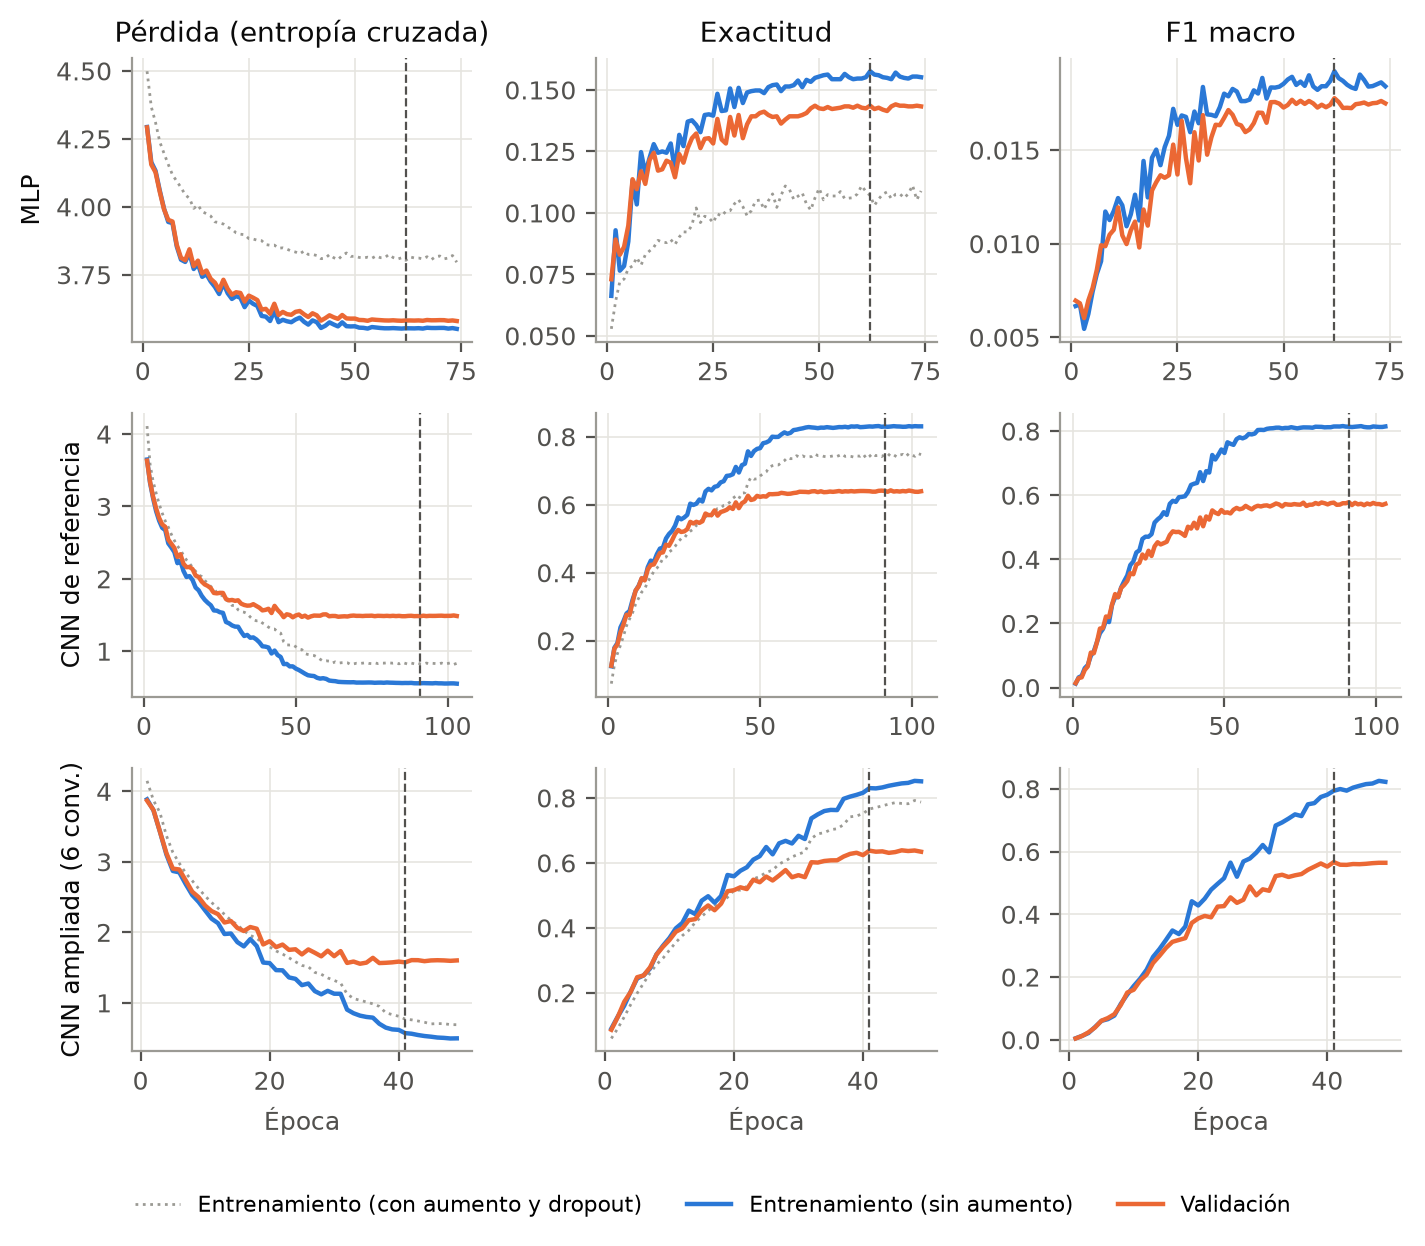

In [7]:
display(Image(filename=str(REPORT / "figures/curvas_modelos.png"), width=900))

## 5. Métricas por clase y desbalance (B2, B3)

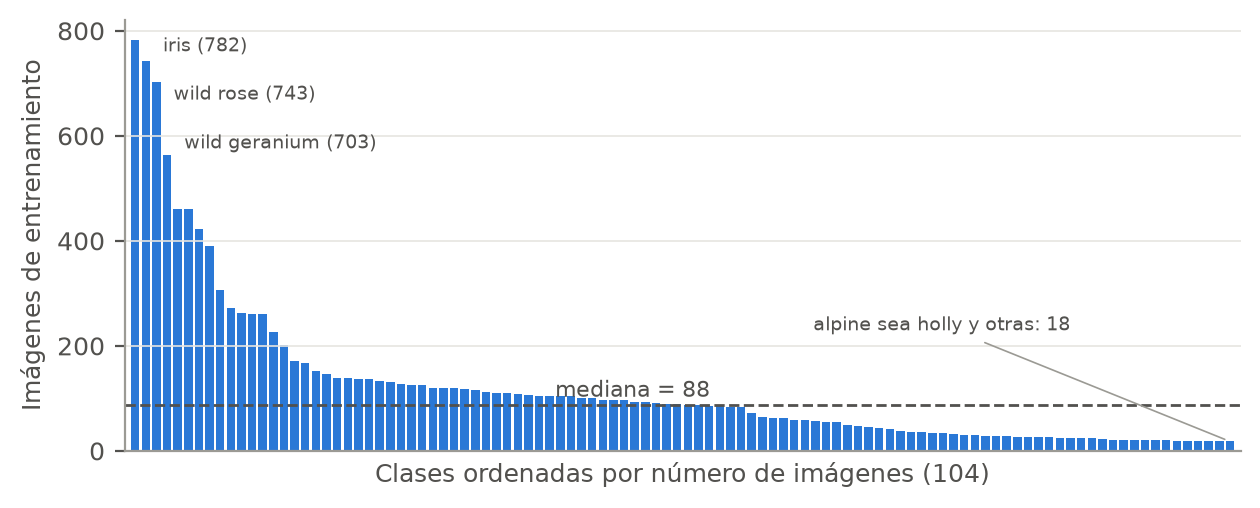

**CNN de referencia: 10 mejores clases**

,label,name,precision,recall,f1,support,train
0,59,pink-yellow dahlia,1.0000,1.0000,1.0000,17,58
1,60,cautleya spicata,1.0000,1.0000,1.0000,8,27
2,36,cape flower,0.9444,1.0000,0.9714,17,57
3,16,purple coneflower,1.0000,0.9375,0.9677,16,55
4,55,bishop of llandaff,0.9412,0.9412,0.9412,17,58
5,63,silverbush,0.8889,1.0000,0.9412,8,28
6,64,californian poppy,0.9375,0.9375,0.9375,16,55
7,57,geranium,0.8947,0.9444,0.9189,18,63
8,58,orange dahlia,0.9000,0.9000,0.9000,10,36
9,65,osteospermum,0.8182,1.0000,0.9000,9,33


**CNN de referencia: 10 peores clases**

,label,name,precision,recall,f1,support,train
0,44,bolero deep blue,0.0000,0.0000,0.0000,5,18
1,38,siam tulip,0.0000,0.0000,0.0000,5,19
2,2,canterbury bells,0.0000,0.0000,0.0000,6,20
3,92,pink quill,0.0000,0.0000,0.0000,7,24
4,31,garden phlox,0.0000,0.0000,0.0000,7,24
5,85,tree mallow,0.2500,0.1111,0.1538,9,29
6,42,sword lily,0.2500,0.1667,0.2000,18,63
7,82,hibiscus,0.2571,0.2308,0.2432,39,134
8,66,spring crocus,0.5000,0.1667,0.2500,6,21
9,15,globe-flower,0.5000,0.1667,0.2500,6,21


Correlación de Spearman entre tamaño de clase y F1: 0.122


In [8]:
display(Image(filename=str(REPORT / "figures/distribucion_clases.png"), width=800))
reference = json.loads(next((EXPERIMENTS / "runs/referencia").glob("*/eval_report.json")).read_text())
per_class = pd.DataFrame(reference["per_class"]).merge(counts[["label", "train"]], on="label")
ordered = per_class.sort_values(["f1", "train"], ascending=[False, False])
display(Markdown("**CNN de referencia: 10 mejores clases**")); display(ordered.head(10).reset_index(drop=True))
display(Markdown("**CNN de referencia: 10 peores clases**")); display(ordered.tail(10).iloc[::-1].reset_index(drop=True))
print("Correlación de Spearman entre tamaño de clase y F1:",
      round(per_class[["train", "f1"]].corr(method="spearman").iloc[0, 1], 3))

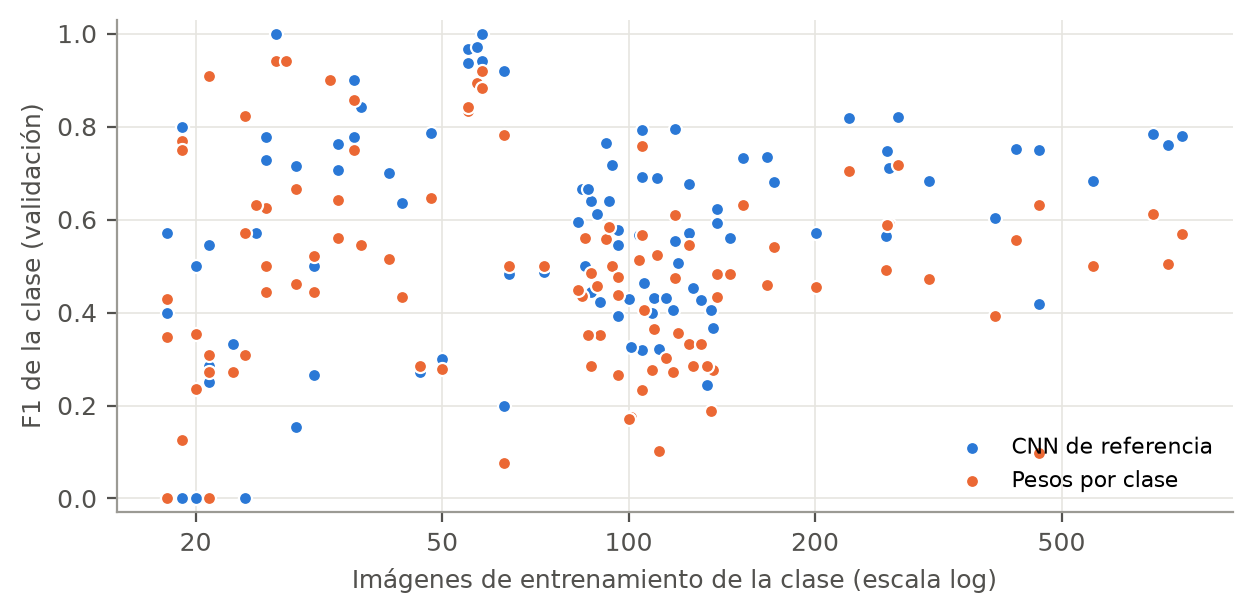

,val_exactitud,val_f1_macro,f1_10_clases_menores,f1_10_clases_mayores,clases_f1_cero
experimento,,,,,
referencia,0.6406,0.5784,0.3607,0.7034,5
class_weight,0.4887,0.4881,0.3281,0.5050,2


In [9]:
display(Image(filename=str(REPORT / "figures/f1_vs_tamano_clase.png"), width=800))
display(results.set_index("experimento").loc[["referencia", "class_weight"],
        ["val_exactitud", "val_f1_macro", "f1_10_clases_menores", "f1_10_clases_mayores", "clases_f1_cero"]])

## 6. Regularización con evidencia (B4) e hiperparámetros (B5)

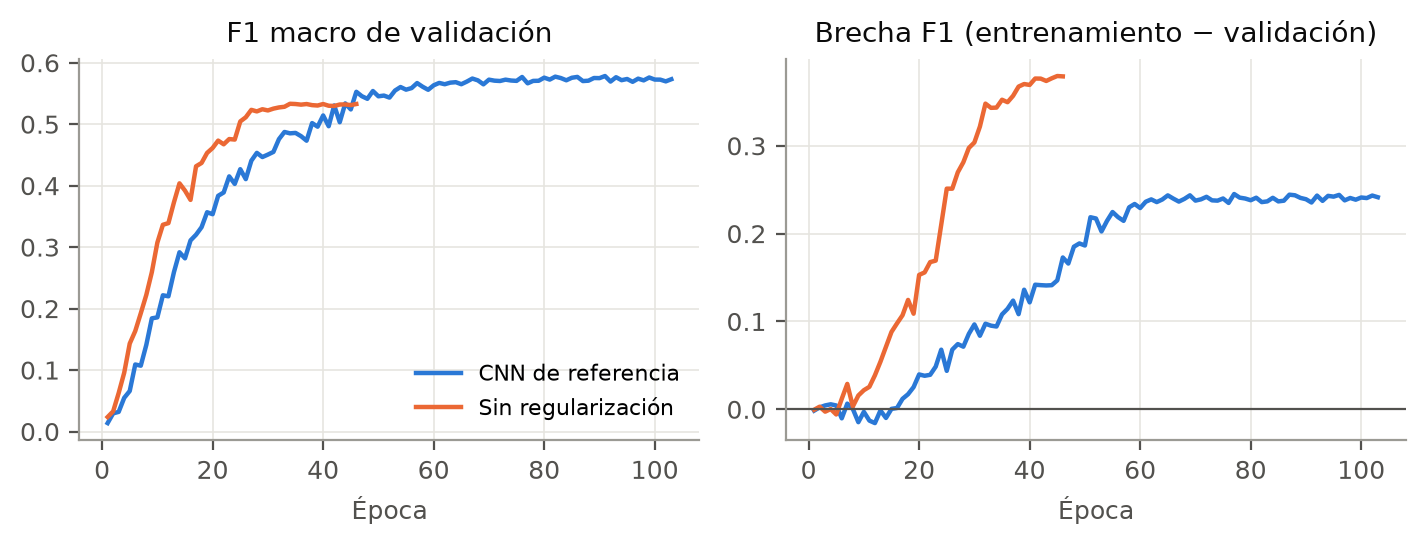

**Ablación de regularización**

,dropout,aumento,optimizador,l2,label_smoothing,val_f1_macro,train_f1_macro,brecha_f1
experimento,,,,,,,,
referencia,0.5,True,adamw,0.0,0.0,0.5784,0.8138,0.2354
sin_regularizacion,0.0,False,adam,0.0,0.0,0.5332,0.8767,0.3435


**Hiperparámetros (uno a la vez)**

,lr,dropout,img_size,val_exactitud,val_f1_macro,brecha_f1,segundos_entrenamiento
experimento,,,,,,,
referencia,0.0010,0.5,112,0.6406,0.5784,0.2354,1181.6
lr_3e-4,0.0003,0.5,112,0.5418,0.4605,0.0936,1350.8
dropout_0.3,0.0010,0.3,112,0.6196,0.5596,0.2561,901.3


In [10]:
display(Image(filename=str(REPORT / "figures/curvas_regularizacion.png"), width=900))
regularization = ["referencia", "sin_dropout", "sin_aumento", "sin_weight_decay", "sin_regularizacion", "l2", "label_smoothing"]
hyper = ["referencia", "lr_3e-4", "dropout_0.3", "res_160"]
table = results.set_index("experimento")
display(Markdown("**Ablación de regularización**"))
display(table.loc[[k for k in regularization if k in table.index],
                  ["dropout", "aumento", "optimizador", "l2", "label_smoothing", "val_f1_macro", "train_f1_macro", "brecha_f1"]])
display(Markdown("**Hiperparámetros (uno a la vez)**"))
display(table.loc[[k for k in hyper if k in table.index],
                  ["lr", "dropout", "img_size", "val_exactitud", "val_f1_macro", "brecha_f1", "segundos_entrenamiento"]])

## 7. MLP vs. CNN vs. transfer learning (B6, B7)

In [11]:
display(table.loc[[k for k in ["mlp", "referencia", "cnn_ampliada"] if k in table.index],
                  ["parametros", "img_size", "val_exactitud", "val_f1_macro", "train_f1_macro", "brecha_f1"]])

,parametros,img_size,val_exactitud,val_f1_macro,train_f1_macro,brecha_f1
experimento,,,,,,
mlp,9660776,112,0.1436,0.0178,0.0192,0.0014
referencia,480936,112,0.6406,0.5784,0.8138,0.2354
cnn_ampliada,1218600,112,0.6377,0.5663,0.7936,0.2273
